# 05 · Tree Models: Decision Tree, Random Forest, Gradient Boosting

**Goal:** fit the non-linear models (lessons 14 and 15), which can follow the curved age–price relation and
combinations of features (a diesel pickup is worth more than "diesel" plus "pickup" separately), and compare them
with the linear models from notebook 04.

All models use the tree preprocessor (median-impute numbers, one-hot categories, no scaling) and `log(price)` as
the target; predictions are turned back into dollars before scoring.

**Tuning strategy.** The training set has 166,115 rows × 439 columns. Random Forest and Gradient Boosting take
minutes per fit at that size, so a full grid search would take hours. Following lesson 13, hyper-parameters are
chosen with `GridSearchCV` (3-fold) on a **random sample of 40,000 training rows**, then the best setting is refit
**once on the full training set** and scored once on the test set. The Decision Tree is fast enough to tune on the
full training set.

⏱️ *Runtime: about 70 minutes. Most of it is Gradient Boosting (about 20 minutes of tuning and a 42-minute final fit), because boosting cannot use more than one CPU core.*

In [1]:
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

sys.path.append('../src')
from prep import (load_data, split, add_model_top, tree_preprocessor, evaluate,
                  save_result, save_params, RANDOM_STATE)

sns.set_theme(style='whitegrid')
df = load_data()
X_train, X_test, y_train, y_test = split(df)
X_train, X_test = add_model_top(X_train, X_test)
y_train_log = np.log(y_train)

sample = X_train.sample(40_000, random_state=RANDOM_STATE).index
X_tune, y_tune_log = X_train.loc[sample], y_train_log.loc[sample]
print('train', X_train.shape, '| test', X_test.shape, '| tuning sample', X_tune.shape)

test_preds = pd.DataFrame({'price': y_test})
train_vs_test = []

def score(name, model):
    # Score on test (once) and on train, to show overfitting; store the predictions
    pred_test = np.exp(model.predict(X_test))
    pred_train = np.exp(model.predict(X_train))
    test_preds[name] = pred_test.round(0)
    train_vs_test.append({'model': name,
                          'train_mae': mean_absolute_error(y_train, pred_train),
                          'test_mae': mean_absolute_error(y_test, pred_test)})
    return save_result(evaluate(name, y_test, pred_test))

train (166115, 20) | test (41529, 20) | tuning sample (40000, 20)


## 1. Decision Tree (CART regression tree, lesson 14)

### A shallow tree to see how it splits
A depth-3 tree is too simple to predict well, but it shows which questions the model asks first.

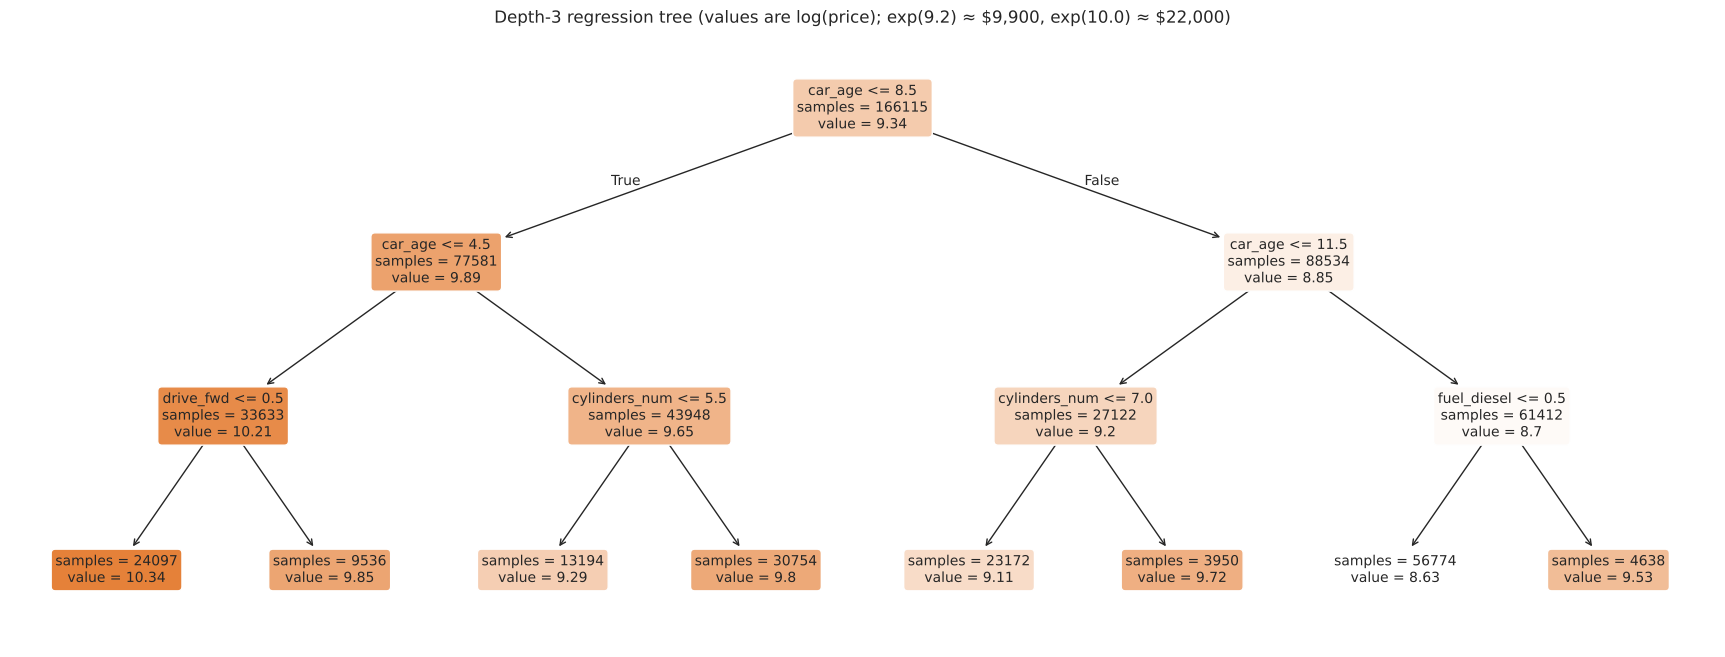

In [2]:
small = make_pipeline(tree_preprocessor(), DecisionTreeRegressor(max_depth=3, random_state=RANDOM_STATE))
small.fit(X_train, y_train_log)

plt.figure(figsize=(22, 8))
plot_tree(small[-1], feature_names=small[0].get_feature_names_out(), filled=True, rounded=True,
          impurity=False, precision=2, fontsize=10)
plt.title(r'Depth-3 regression tree (values are log(price); exp(9.2) ≈ \$9,900, exp(10.0) ≈ \$22,000)')
plt.show()

**What the shallow tree asks first:**

- **Age is the first question, and the tree asks it three times** (8.5, 4.5 and 11.5 years). This matches the EDA,
  where age had the strongest link with price (Spearman −0.71). Mileage does not appear in the first three levels:
  it moves together with age, so once age is known it adds less.
- **Young cars (≤ 4 years):** drive type comes next. Non-front-wheel-drive cars (4WD trucks, rear-wheel drive)
  average about \$30,900, front-wheel-drive cars about \$19,000.
- **Ages 5–8 and 9–11:** the number of cylinders splits them. Bigger engines (6+ or 8 cylinders, mostly trucks and
  SUVs) are worth roughly \$7,200–7,600 more than smaller ones (\$18,000 vs \$10,800, and \$16,600 vs \$9,000).
- **Cars older than 11 years:** diesel decides. Old diesels average about \$13,800, old non-diesels about \$5,600.

The leaf values are averages of log(price), so the dollar figures are approximate (exp of the shown value).
A depth-3 tree has only 8 possible answers, which is why the tuned tree below is much deeper.

### Tuning the full tree

In [3]:
t = time.time()
dt = GridSearchCV(make_pipeline(tree_preprocessor(), DecisionTreeRegressor(random_state=RANDOM_STATE)),
                  {'decisiontreeregressor__max_depth': [10, 15, 20, 30],
                   'decisiontreeregressor__min_samples_leaf': [5, 20, 50]},
                  cv=3, scoring='neg_mean_absolute_error', n_jobs=-1)
dt.fit(X_train, y_train_log)
print(f'{time.time() - t:.0f} s | best:', dt.best_params_)

res = pd.DataFrame(dt.cv_results_)
res.pivot(index='param_decisiontreeregressor__max_depth',
          columns='param_decisiontreeregressor__min_samples_leaf', values='mean_test_score').round(4)

100 s | best: {'decisiontreeregressor__max_depth': 15, 'decisiontreeregressor__min_samples_leaf': 5}


param_decisiontreeregressor__min_samples_leaf,5,20,50
param_decisiontreeregressor__max_depth,,,
10,-0.3274,-0.3280,-0.3291
15,-0.3089,-0.3111,-0.3151
20,-0.3098,-0.3091,-0.3140
30,-0.3141,-0.3096,-0.3141


In [4]:
save_params('Decision Tree', dt.best_params_)
score('Decision Tree', dt.best_estimator_)

,model,target,mae,rmse,r2,mae_pct_of_median,median_abs_error
0,Baseline (median price),price,9675.191,14552.936,-0.086,80.748,6650.000
5,Decision Tree,log(price),4195.589,7433.051,0.717,35.016,2354.399
1,Lasso,log(price),4151.412,7829.515,0.686,34.647,2150.222
2,Linear Regression,log(price),4150.916,7886.378,0.681,34.643,2150.929
3,Ridge,log(price),4149.765,7862.822,0.683,34.633,2150.480
4,ElasticNet,log(price),4149.163,7767.575,0.690,34.628,2151.550


## 2. Random Forest (lesson 15)

Many deep trees, each trained on a bootstrap sample and a random subset of columns at every split; their
average is much more stable than one tree.

In [5]:
t = time.time()
rf_search = GridSearchCV(
    make_pipeline(tree_preprocessor(), RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)),
    {'randomforestregressor__max_features': [0.3, 0.6],
     'randomforestregressor__min_samples_leaf': [1, 3]},
    cv=3, scoring='neg_mean_absolute_error')
rf_search.fit(X_tune, y_tune_log)
print(f'{time.time() - t:.0f} s | best on the sample:', rf_search.best_params_)
pd.DataFrame(rf_search.cv_results_)[['param_randomforestregressor__max_features',
                                     'param_randomforestregressor__min_samples_leaf', 'mean_test_score']].round(4)

137 s | best on the sample: {'randomforestregressor__max_features': 0.3, 'randomforestregressor__min_samples_leaf': 1}


,param_randomforestregressor__max_features,param_randomforestregressor__min_samples_leaf,mean_test_score
0,0.3,1,-0.2697
1,0.3,3,-0.2812
2,0.6,1,-0.2727
3,0.6,3,-0.2836


In [6]:
t = time.time()
rf = rf_search.best_estimator_.fit(X_train, y_train_log)     # refit the best setting on all training rows
print(f'Final fit on {len(X_train):,} rows: {time.time() - t:.0f} s')
save_params('Random Forest', rf_search.best_params_)
score('Random Forest', rf)

Final fit on 166,115 rows: 88 s


,model,target,mae,rmse,r2,mae_pct_of_median,median_abs_error
0,Baseline (median price),price,9675.191,14552.936,-0.086,80.748,6650.000
1,Decision Tree,log(price),4195.589,7433.051,0.717,35.016,2354.399
2,Lasso,log(price),4151.412,7829.515,0.686,34.647,2150.222
3,Linear Regression,log(price),4150.916,7886.378,0.681,34.643,2150.929
4,Ridge,log(price),4149.765,7862.822,0.683,34.633,2150.480
5,ElasticNet,log(price),4149.163,7767.575,0.690,34.628,2151.550
6,Random Forest,log(price),3231.402,6184.166,0.804,26.969,1745.899


## 3. Gradient Boosting (lesson 15)

Trees are added one at a time, each one correcting the errors of the trees before it. Shallow trees, a small
learning rate and `subsample=0.8` (each tree sees 80% of the rows) keep it from overfitting.

In [7]:
t = time.time()
gb_search = GridSearchCV(
    make_pipeline(tree_preprocessor(),
                  GradientBoostingRegressor(learning_rate=0.1, subsample=0.8, random_state=RANDOM_STATE)),
    {'gradientboostingregressor__n_estimators': [300, 600],
     'gradientboostingregressor__max_depth': [4, 6]},
    cv=3, scoring='neg_mean_absolute_error', n_jobs=-1)
gb_search.fit(X_tune, y_tune_log)
print(f'{time.time() - t:.0f} s | best on the sample:', gb_search.best_params_)
pd.DataFrame(gb_search.cv_results_)[['param_gradientboostingregressor__n_estimators',
                                     'param_gradientboostingregressor__max_depth', 'mean_test_score']].round(4)

1287 s | best on the sample: {'gradientboostingregressor__max_depth': 6, 'gradientboostingregressor__n_estimators': 600}


,param_gradientboostingregressor__n_estimators,param_gradientboostingregressor__max_depth,mean_test_score
0,300,4,-0.2676
1,600,4,-0.2559
2,300,6,-0.2563
3,600,6,-0.2483


In [8]:
t = time.time()
gb = gb_search.best_estimator_.fit(X_train, y_train_log)
print(f'Final fit on {len(X_train):,} rows: {time.time() - t:.0f} s')
save_params('Gradient Boosting', gb_search.best_params_)
score('Gradient Boosting', gb)

Final fit on 166,115 rows: 2543 s


,model,target,mae,rmse,r2,mae_pct_of_median,median_abs_error
0,Baseline (median price),price,9675.191,14552.936,-0.086,80.748,6650.000
1,Decision Tree,log(price),4195.589,7433.051,0.717,35.016,2354.399
2,Lasso,log(price),4151.412,7829.515,0.686,34.647,2150.222
3,Linear Regression,log(price),4150.916,7886.378,0.681,34.643,2150.929
4,Ridge,log(price),4149.765,7862.822,0.683,34.633,2150.480
5,ElasticNet,log(price),4149.163,7767.575,0.690,34.628,2151.550
7,Gradient Boosting,log(price),3303.451,6348.464,0.793,27.570,1760.566
6,Random Forest,log(price),3231.402,6184.166,0.804,26.969,1745.899


## 4. Overfitting check: training error vs test error

In [9]:
tvt = pd.DataFrame(train_vs_test).set_index('model')
tvt['gap'] = tvt['test_mae'] - tvt['train_mae']
tvt.round(0)

,train_mae,test_mae,gap
model,,,
Decision Tree,3654.0,4196.0,541.0
Random Forest,1222.0,3231.0,2010.0
Gradient Boosting,3023.0,3303.0,281.0


**Reading the gaps:**

- **Decision Tree:** \$3,654 on training vs \$4,196 on test. A moderate gap; `min_samples_leaf=5` stops it from
  memorising single cars, but one tree still cannot beat the linear models on typical error.
- **Random Forest:** \$1,222 on training vs \$3,231 on test, the biggest gap. With `min_samples_leaf=1` each tree
  grows until its leaves hold single cars, so it nearly memorises the training set; averaging 100 trees is what
  keeps the *test* error low. Cross-validation picked this setting (log-MAE 0.270 vs 0.281 with leaf 3), so the gap
  is expected for a forest and is not a reason to reject it.
- **Gradient Boosting:** \$3,023 vs \$3,303, the smallest gap. Its predictions on new cars are the most
  consistent with what it learned.

**A caution:** on the 40,000-row tuning sample Gradient Boosting scored better than Random Forest in
cross-validation (log-MAE 0.248 vs 0.270), but on the full data Random Forest wins. A forest with one-car leaves
gains a lot from near-identical listings. Exact reposts were removed (notebook 03 found 0 test cars with a twin in
training), but a car re-posted with a slightly changed price or mileage would still look like a "neighbour" in
training. Part of the forest's lead may come from that, so both models go forward to the next stage.

## 5. All models so far (test set)

In [10]:
test_preds.to_csv('../results/test_predictions.csv', index=False)
results = pd.read_csv('../results/metrics.csv').sort_values('mae')
results.round(3)

,model,target,mae,rmse,r2,mae_pct_of_median,median_abs_error
7,Random Forest,log(price),3231.402,6184.166,0.804,26.969,1745.899
6,Gradient Boosting,log(price),3303.451,6348.464,0.793,27.570,1760.566
5,ElasticNet,log(price),4149.163,7767.575,0.690,34.628,2151.550
4,Ridge,log(price),4149.765,7862.822,0.683,34.633,2150.480
3,Linear Regression,log(price),4150.916,7886.378,0.681,34.643,2150.929
2,Lasso,log(price),4151.412,7829.515,0.686,34.647,2150.222
1,Decision Tree,log(price),4195.589,7433.051,0.717,35.016,2354.399
0,Baseline (median price),price,9675.191,14552.936,-0.086,80.748,6650.000


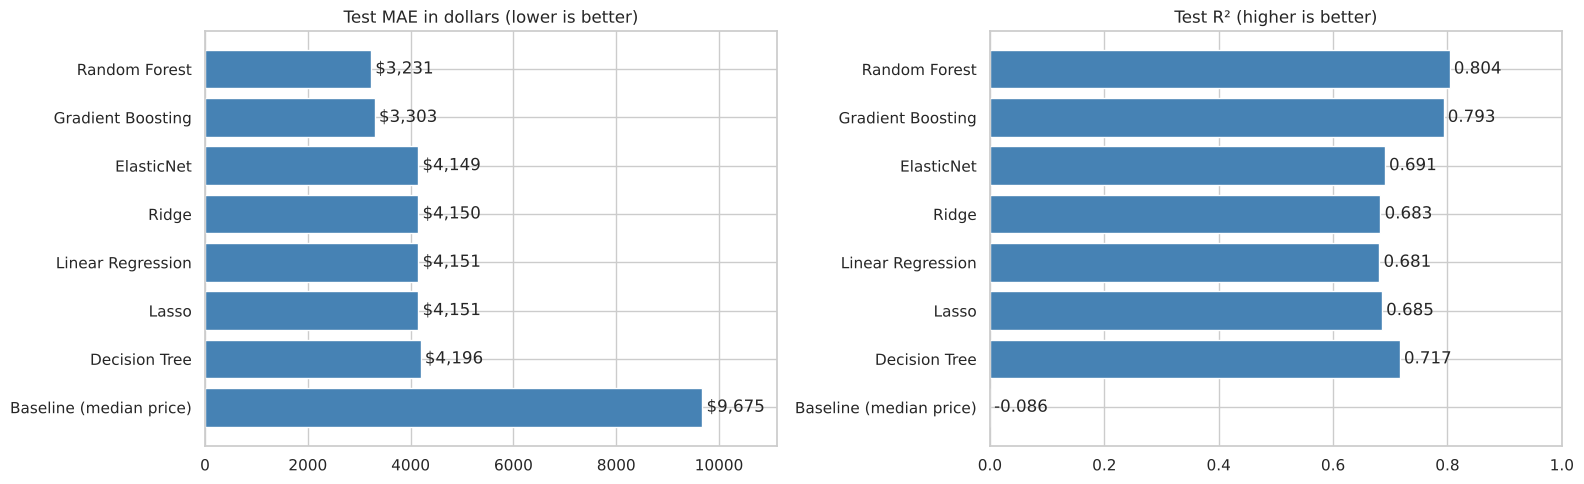

In [11]:
plot = results.sort_values('mae', ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].barh(plot['model'], plot['mae'], color='steelblue')
axes[0].bar_label(axes[0].containers[0], labels=[f'${v:,.0f}' for v in plot['mae']], padding=3)
axes[0].set_title('Test MAE in dollars (lower is better)')
axes[0].set_xlim(0, plot['mae'].max() * 1.15)
axes[1].barh(plot['model'], plot['r2'].clip(lower=0), color='steelblue')   # negative R² drawn as 0
axes[1].bar_label(axes[1].containers[0], labels=[f'{v:.3f}' for v in plot['r2']], padding=3)
axes[1].set_title('Test R² (higher is better)')
axes[1].set_xlim(0, 1)
plt.tight_layout()
plt.show()

In [12]:
# Error by price band for the best model: where is the model weakest?
best = results.iloc[0]['model']
bands = pd.cut(test_preds['price'], [0, 5000, 10000, 20000, 35000, 150000],
               labels=['< $5k', '$5-10k', '$10-20k', '$20-35k', '> $35k'])
err = (test_preds[best] - test_preds['price']).abs()
by_band = pd.DataFrame({'cars': bands.value_counts(sort=False),
                        'mae_$': err.groupby(bands, observed=True).mean().round(0),
                        'mae_%_of_price': (err / test_preds['price'] * 100).groupby(bands, observed=True).mean().round(1)})
print('Best model:', best)
by_band

Best model: Random Forest


,cars,mae_$,mae_%_of_price
price,,,
< $5k,7852,1796.0,75.2
$5-10k,10764,1655.0,22.0
$10-20k,11877,2686.0,18.1
$20-35k,7337,4413.0,16.4
> $35k,3699,10273.0,19.1


## Summary

| Model | Test MAE | RMSE | R² | Median error |
| --- | --- | --- | --- | --- |
| **Random Forest** | **\$3,231** | \$6,184 | **0.804** | \$1,746 |
| Gradient Boosting | \$3,303 | \$6,348 | 0.793 | \$1,761 |
| ElasticNet (best linear) | \$4,149 | \$7,768 | 0.690 | \$2,152 |
| Decision Tree | \$4,196 | \$7,433 | 0.717 | \$2,354 |
| Baseline (median price) | \$9,675 | \$14,553 | −0.087 | \$6,650 |

- **The ensembles are clearly the best.** Random Forest cuts the typical error from \$4,149 (best linear model) to
  **\$3,231, 22% lower**, and explains 80% of the price variation. Against the baseline the error falls by 67%.
  Gradient Boosting is only \$72 behind.
- **A single tree is not enough.** The tuned Decision Tree has a slightly worse MAE than the linear models
  (\$4,196), though it makes fewer very large mistakes (lower RMSE).
- **Where the best model is weak:** cars under \$5,000. The dollar error is small (\$1,796) but it is 75% of the
  price on average, because cheap listings include junk cars, parts cars and prices that do not match the details.
  For cars between \$10,000 and \$35,000 the error is 16–18% of the price; above \$35,000 it is \$10,273 (19%).
- **Tuning notes:** the Gradient Boosting grid picked its largest values (600 trees, depth 6), so more trees might
  help a little. Its final fit took about 42 minutes because boosting builds trees one after another on one core,
  while the forest took 1.5 minutes using all cores.

**Decision for the next stages:** Random Forest is the best-scoring model and becomes the main model, with
Gradient Boosting kept as the close runner-up (smaller overfitting gap). Linear Regression stays as the
explaining model, because its coefficients give a price change per year and per feature in plain numbers.
Next: explain what drives the predictions (feature importance and partial dependence, lesson 16).